# Avance 1 — Pronóstico de órdenes entrantes (scans recibidos por día)

**BCD5105 · Modelado matemático · III Cuatrimestre 2026 · Lead University**

**Grupo:** _(número)_

**Integrantes:** _(nombres completos)_

Este notebook reproduce el análisis exploratorio y el primer modelo (SARIMA con período semanal) del avance. Se ejecuta de principio a fin en un entorno limpio de Colab (Python 3). Los datos están incluidos en la celda 3, así que no depende de ningún enlace externo.

Contenido:
1. Configuración, versiones y semilla
2. Datos y su origen
3. Análisis exploratorio (estadísticas y cuatro figuras)
4. Primer modelo: identificación del SARIMA
5. Validación de ventana expansiva contra los modelos de referencia
6. Diagnóstico de residuos y pronóstico a 14 días

## 1. Configuración, versiones y semilla

In [1]:
%pip install -q statsforecast holidays

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.2.2
[notice] To update, run: C:\Users\Light Force CR\venvs\forecast_pi\Scripts\python.exe -m pip install --upgrade pip


In [2]:
import io, os, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import statsmodels, statsforecast, holidays, scipy
from scipy.stats import wilcoxon
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import acf, adfuller, kpss
from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsforecast import StatsForecast
from statsforecast.models import SeasonalNaive, SeasonalWindowAverage, AutoETS, AutoARIMA, ARIMA

warnings.filterwarnings("ignore")
SEMILLA = 2026
random.seed(SEMILLA)
np.random.seed(SEMILLA)

print("pandas", pd.__version__, "| numpy", np.__version__, "| scipy", scipy.__version__)
print("statsmodels", statsmodels.__version__, "| statsforecast", statsforecast.__version__, "| holidays", holidays.__version__)

# Estilo de las figuras: paleta categórica validada (azul, naranja, aqua), rejilla tenue, sin bordes superior/derecho
C = dict(azul="#2a78d6", naranja="#eb6834", aqua="#1baf7a", tinta="#0b0b0b", tinta2="#52514e",
         tenue="#898781", rejilla="#e1e0d9", base="#c3c2b7", fondo="#fcfcfb")
plt.rcParams.update({
    "figure.facecolor": C["fondo"], "axes.facecolor": C["fondo"], "axes.edgecolor": C["base"],
    "axes.labelcolor": C["tinta2"], "xtick.color": C["tenue"], "ytick.color": C["tenue"],
    "text.color": C["tinta"], "axes.grid": True, "grid.color": C["rejilla"], "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "font.size": 9, "axes.titlesize": 10,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "savefig.dpi": 200,
    "savefig.bbox": "tight", "figure.dpi": 110, "legend.frameon": False})
os.makedirs("figuras", exist_ok=True)

C:\Users\Light Force CR\venvs\forecast_pi\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


pandas 2.3.3 | numpy 2.5.4 | scipy 1.18.1
statsmodels 0.15.0 | statsforecast 2.1.1 | holidays 0.107


## 2. Datos y su origen

**Fuente:** base de datos analítica de LightForce Orthodontics (Databricks), tabla `analytics.manufacturing.mfg_all_orders`, consultada el 26 de octubre de 2026 con autorización de la empresa. Cada fila de la tabla es un caso de manufactura (un _epic_ de Jira).

**Definición de orden entrante:** caso nuevo (`order_type = 'New case'`) con fecha de recepción del scan (`scan_received_date`). Los _Reorder_ no tienen scan, porque reutilizan el escaneo original, y por eso quedan fuera. La fecha se pasa de UTC a hora del este de EE. UU. (ET) antes de contar por día. Se incluyen todas las etapas de tratamiento y todos los estados, incluso casos luego cancelados, porque la demanda llegó de todos modos.

Consulta usada (los días sin órdenes se completan con 0 mediante una tabla de fechas; no hubo ninguno):

```sql
WITH spine AS (
  SELECT explode(sequence(date'2023-01-01', date'2026-10-25', interval 1 day)) AS d
), c AS (
  SELECT to_date(from_utc_timestamp(scan_received_date, 'America/New_York')) AS d, count(*) AS n
  FROM analytics.manufacturing.mfg_all_orders
  WHERE order_type = 'New case' AND scan_received_date IS NOT NULL
  GROUP BY 1
)
SELECT s.d AS fecha, coalesce(c.n, 0) AS ordenes
FROM spine s LEFT JOIN c ON s.d = c.d
ORDER BY 1
```

Se usa desde el 1 de enero de 2023 porque entre 2019 y 2022 la empresa estaba en rampa de crecimiento (de unas decenas a miles de casos por mes) y el nivel se estabiliza a partir de 2023. El último día completo es el 25 de octubre de 2026.

In [3]:
CSV_DATOS = '''fecha,ordenes
2023-01-01,2
2023-01-02,48
2023-01-03,118
2023-01-04,119
2023-01-05,137
2023-01-06,137
2023-01-07,7
2023-01-08,7
2023-01-09,203
2023-01-10,196
2023-01-11,156
2023-01-12,147
2023-01-13,114
2023-01-14,13
2023-01-15,37
2023-01-16,73
2023-01-17,293
2023-01-18,208
2023-01-19,138
2023-01-20,138
2023-01-21,12
2023-01-22,2
2023-01-23,201
2023-01-24,226
2023-01-25,164
2023-01-26,136
2023-01-27,132
2023-01-28,6
2023-01-29,64
2023-01-30,132
2023-01-31,124
2023-02-01,214
2023-02-02,207
2023-02-03,105
2023-02-04,5
2023-02-05,4
2023-02-06,174
2023-02-07,135
2023-02-08,165
2023-02-09,156
2023-02-10,123
2023-02-11,7
2023-02-12,25
2023-02-13,181
2023-02-14,142
2023-02-15,203
2023-02-16,179
2023-02-17,99
2023-02-18,20
2023-02-19,3
2023-02-20,152
2023-02-21,176
2023-02-22,177
2023-02-23,194
2023-02-24,106
2023-02-25,8
2023-02-26,2
2023-02-27,181
2023-02-28,151
2023-03-01,196
2023-03-02,132
2023-03-03,153
2023-03-04,5
2023-03-05,9
2023-03-06,163
2023-03-07,193
2023-03-08,191
2023-03-09,194
2023-03-10,98
2023-03-11,6
2023-03-12,5
2023-03-13,174
2023-03-14,174
2023-03-15,150
2023-03-16,169
2023-03-17,170
2023-03-18,5
2023-03-19,9
2023-03-20,176
2023-03-21,187
2023-03-22,145
2023-03-23,187
2023-03-24,117
2023-03-25,11
2023-03-26,5
2023-03-27,174
2023-03-28,159
2023-03-29,181
2023-03-30,195
2023-03-31,148
2023-04-01,10
2023-04-02,33
2023-04-03,183
2023-04-04,211
2023-04-05,181
2023-04-06,134
2023-04-07,154
2023-04-08,11
2023-04-09,7
2023-04-10,233
2023-04-11,147
2023-04-12,222
2023-04-13,183
2023-04-14,134
2023-04-15,6
2023-04-16,8
2023-04-17,172
2023-04-18,227
2023-04-19,175
2023-04-20,223
2023-04-21,99
2023-04-22,3
2023-04-23,3
2023-04-24,158
2023-04-25,151
2023-04-26,209
2023-04-27,151
2023-04-28,134
2023-04-29,18
2023-04-30,14
2023-05-01,121
2023-05-02,196
2023-05-03,235
2023-05-04,193
2023-05-05,112
2023-05-06,7
2023-05-07,11
2023-05-08,167
2023-05-09,228
2023-05-10,149
2023-05-11,236
2023-05-12,118
2023-05-13,12
2023-05-14,15
2023-05-15,159
2023-05-16,223
2023-05-17,198
2023-05-18,204
2023-05-19,98
2023-05-20,19
2023-05-21,2
2023-05-22,169
2023-05-23,140
2023-05-24,241
2023-05-25,188
2023-05-26,142
2023-05-27,4
2023-05-28,39
2023-05-29,29
2023-05-30,182
2023-05-31,224
2023-06-01,187
2023-06-02,91
2023-06-03,3
2023-06-04,12
2023-06-05,187
2023-06-06,163
2023-06-07,216
2023-06-08,199
2023-06-09,129
2023-06-10,12
2023-06-11,50
2023-06-12,205
2023-06-13,207
2023-06-14,192
2023-06-15,226
2023-06-16,166
2023-06-17,50
2023-06-18,15
2023-06-19,155
2023-06-20,316
2023-06-21,178
2023-06-22,275
2023-06-23,147
2023-06-24,23
2023-06-25,12
2023-06-26,218
2023-06-27,197
2023-06-28,207
2023-06-29,243
2023-06-30,158
2023-07-01,16
2023-07-02,51
2023-07-03,79
2023-07-04,48
2023-07-05,174
2023-07-06,129
2023-07-07,123
2023-07-08,6
2023-07-09,40
2023-07-10,137
2023-07-11,233
2023-07-12,251
2023-07-13,252
2023-07-14,155
2023-07-15,5
2023-07-16,8
2023-07-17,227
2023-07-18,201
2023-07-19,236
2023-07-20,235
2023-07-21,168
2023-07-22,15
2023-07-23,12
2023-07-24,132
2023-07-25,291
2023-07-26,217
2023-07-27,240
2023-07-28,175
2023-07-29,42
2023-07-30,55
2023-07-31,156
2023-08-01,271
2023-08-02,152
2023-08-03,240
2023-08-04,132
2023-08-05,29
2023-08-06,11
2023-08-07,165
2023-08-08,175
2023-08-09,204
2023-08-10,182
2023-08-11,140
2023-08-12,27
2023-08-13,30
2023-08-14,158
2023-08-15,286
2023-08-16,209
2023-08-17,203
2023-08-18,164
2023-08-19,17
2023-08-20,40
2023-08-21,193
2023-08-22,243
2023-08-23,254
2023-08-24,212
2023-08-25,132
2023-08-26,38
2023-08-27,25
2023-08-28,214
2023-08-29,220
2023-08-30,227
2023-08-31,247
2023-09-01,117
2023-09-02,16
2023-09-03,19
2023-09-04,63
2023-09-05,192
2023-09-06,199
2023-09-07,177
2023-09-08,107
2023-09-09,12
2023-09-10,42
2023-09-11,173
2023-09-12,191
2023-09-13,225
2023-09-14,201
2023-09-15,123
2023-09-16,32
2023-09-17,30
2023-09-18,245
2023-09-19,220
2023-09-20,216
2023-09-21,199
2023-09-22,124
2023-09-23,27
2023-09-24,25
2023-09-25,170
2023-09-26,274
2023-09-27,222
2023-09-28,196
2023-09-29,147
2023-09-30,28
2023-10-01,18
2023-10-02,224
2023-10-03,230
2023-10-04,227
2023-10-05,204
2023-10-06,133
2023-10-07,26
2023-10-08,30
2023-10-09,152
2023-10-10,225
2023-10-11,236
2023-10-12,213
2023-10-13,147
2023-10-14,22
2023-10-15,21
2023-10-16,190
2023-10-17,267
2023-10-18,222
2023-10-19,230
2023-10-20,133
2023-10-21,23
2023-10-22,35
2023-10-23,211
2023-10-24,242
2023-10-25,225
2023-10-26,238
2023-10-27,155
2023-10-28,12
2023-10-29,24
2023-10-30,234
2023-10-31,217
2023-11-01,193
2023-11-02,260
2023-11-03,119
2023-11-04,22
2023-11-05,33
2023-11-06,226
2023-11-07,237
2023-11-08,236
2023-11-09,230
2023-11-10,145
2023-11-11,20
2023-11-12,32
2023-11-13,204
2023-11-14,230
2023-11-15,253
2023-11-16,210
2023-11-17,133
2023-11-18,28
2023-11-19,32
2023-11-20,204
2023-11-21,261
2023-11-22,197
2023-11-23,79
2023-11-24,60
2023-11-25,15
2023-11-26,45
2023-11-27,186
2023-11-28,210
2023-11-29,251
2023-11-30,249
2023-12-01,116
2023-12-02,31
2023-12-03,25
2023-12-04,205
2023-12-05,262
2023-12-06,251
2023-12-07,214
2023-12-08,138
2023-12-09,17
2023-12-10,48
2023-12-11,189
2023-12-12,239
2023-12-13,263
2023-12-14,220
2023-12-15,129
2023-12-16,44
2023-12-17,40
2023-12-18,193
2023-12-19,233
2023-12-20,232
2023-12-21,262
2023-12-22,144
2023-12-23,23
2023-12-24,11
2023-12-25,11
2023-12-26,86
2023-12-27,124
2023-12-28,153
2023-12-29,65
2023-12-30,21
2023-12-31,9
2024-01-01,10
2024-01-02,168
2024-01-03,208
2024-01-04,204
2024-01-05,156
2024-01-06,30
2024-01-07,27
2024-01-08,212
2024-01-09,285
2024-01-10,248
2024-01-11,230
2024-01-12,139
2024-01-13,31
2024-01-14,21
2024-01-15,239
2024-01-16,270
2024-01-17,239
2024-01-18,274
2024-01-19,139
2024-01-20,15
2024-01-21,47
2024-01-22,221
2024-01-23,273
2024-01-24,265
2024-01-25,247
2024-01-26,112
2024-01-27,12
2024-01-28,44
2024-01-29,185
2024-01-30,244
2024-01-31,220
2024-02-01,245
2024-02-02,130
2024-02-03,18
2024-02-04,54
2024-02-05,260
2024-02-06,284
2024-02-07,253
2024-02-08,250
2024-02-09,130
2024-02-10,29
2024-02-11,34
2024-02-12,203
2024-02-13,244
2024-02-14,221
2024-02-15,232
2024-02-16,152
2024-02-17,24
2024-02-18,36
2024-02-19,177
2024-02-20,292
2024-02-21,226
2024-02-22,214
2024-02-23,123
2024-02-24,30
2024-02-25,31
2024-02-26,236
2024-02-27,249
2024-02-28,265
2024-02-29,266
2024-03-01,135
2024-03-02,18
2024-03-03,43
2024-03-04,256
2024-03-05,239
2024-03-06,253
2024-03-07,218
2024-03-08,119
2024-03-09,38
2024-03-10,26
2024-03-11,172
2024-03-12,236
2024-03-13,194
2024-03-14,224
2024-03-15,148
2024-03-16,22
2024-03-17,42
2024-03-18,211
2024-03-19,242
2024-03-20,235
2024-03-21,195
2024-03-22,101
2024-03-23,28
2024-03-24,28
2024-03-25,201
2024-03-26,212
2024-03-27,234
2024-03-28,252
2024-03-29,101
2024-03-30,13
2024-03-31,12
2024-04-01,194
2024-04-02,244
2024-04-03,234
2024-04-04,217
2024-04-05,133
2024-04-06,18
2024-04-07,31
2024-04-08,191
2024-04-09,232
2024-04-10,234
2024-04-11,199
2024-04-12,147
2024-04-13,24
2024-04-14,40
2024-04-15,205
2024-04-16,242
2024-04-17,223
2024-04-18,234
2024-04-19,127
2024-04-20,24
2024-04-21,24
2024-04-22,235
2024-04-23,219
2024-04-24,202
2024-04-25,201
2024-04-26,133
2024-04-27,38
2024-04-28,47
2024-04-29,199
2024-04-30,250
2024-05-01,254
2024-05-02,244
2024-05-03,133
2024-05-04,16
2024-05-05,24
2024-05-06,223
2024-05-07,245
2024-05-08,254
2024-05-09,238
2024-05-10,114
2024-05-11,24
2024-05-12,34
2024-05-13,229
2024-05-14,252
2024-05-15,264
2024-05-16,212
2024-05-17,108
2024-05-18,29
2024-05-19,20
2024-05-20,156
2024-05-21,199
2024-05-22,219
2024-05-23,207
2024-05-24,125
2024-05-25,14
2024-05-26,32
2024-05-27,103
2024-05-28,198
2024-05-29,224
2024-05-30,228
2024-05-31,125
2024-06-01,32
2024-06-02,32
2024-06-03,218
2024-06-04,274
2024-06-05,277
2024-06-06,257
2024-06-07,163
2024-06-08,23
2024-06-09,17
2024-06-10,228
2024-06-11,239
2024-06-12,259
2024-06-13,247
2024-06-14,128
2024-06-15,22
2024-06-16,33
2024-06-17,215
2024-06-18,251
2024-06-19,263
2024-06-20,229
2024-06-21,143
2024-06-22,16
2024-06-23,32
2024-06-24,233
2024-06-25,254
2024-06-26,267
2024-06-27,295
2024-06-28,161
2024-06-29,31
2024-06-30,39
2024-07-01,138
2024-07-02,187
2024-07-03,225
2024-07-04,101
2024-07-05,61
2024-07-06,18
2024-07-07,37
2024-07-08,264
2024-07-09,261
2024-07-10,219
2024-07-11,245
2024-07-12,131
2024-07-13,10
2024-07-14,40
2024-07-15,220
2024-07-16,271
2024-07-17,258
2024-07-18,264
2024-07-19,124
2024-07-20,49
2024-07-21,31
2024-07-22,226
2024-07-23,261
2024-07-24,247
2024-07-25,235
2024-07-26,123
2024-07-27,16
2024-07-28,16
2024-07-29,212
2024-07-30,223
2024-07-31,215
2024-08-01,262
2024-08-02,126
2024-08-03,16
2024-08-04,26
2024-08-05,191
2024-08-06,214
2024-08-07,202
2024-08-08,210
2024-08-09,110
2024-08-10,20
2024-08-11,37
2024-08-12,264
2024-08-13,263
2024-08-14,197
2024-08-15,196
2024-08-16,161
2024-08-17,12
2024-08-18,16
2024-08-19,236
2024-08-20,263
2024-08-21,239
2024-08-22,251
2024-08-23,144
2024-08-24,26
2024-08-25,57
2024-08-26,208
2024-08-27,272
2024-08-28,209
2024-08-29,270
2024-08-30,123
2024-08-31,9
2024-09-01,21
2024-09-02,58
2024-09-03,212
2024-09-04,193
2024-09-05,218
2024-09-06,118
2024-09-07,22
2024-09-08,30
2024-09-09,215
2024-09-10,266
2024-09-11,192
2024-09-12,237
2024-09-13,116
2024-09-14,26
2024-09-15,35
2024-09-16,228
2024-09-17,226
2024-09-18,236
2024-09-19,212
2024-09-20,111
2024-09-21,23
2024-09-22,29
2024-09-23,218
2024-09-24,236
2024-09-25,247
2024-09-26,238
2024-09-27,122
2024-09-28,33
2024-09-29,35
2024-09-30,226
2024-10-01,277
2024-10-02,210
2024-10-03,229
2024-10-04,131
2024-10-05,26
2024-10-06,20
2024-10-07,224
2024-10-08,267
2024-10-09,195
2024-10-10,188
2024-10-11,150
2024-10-12,33
2024-10-13,16
2024-10-14,134
2024-10-15,273
2024-10-16,226
2024-10-17,217
2024-10-18,116
2024-10-19,22
2024-10-20,37
2024-10-21,185
2024-10-22,243
2024-10-23,237
2024-10-24,204
2024-10-25,123
2024-10-26,18
2024-10-27,25
2024-10-28,210
2024-10-29,232
2024-10-30,252
2024-10-31,201
2024-11-01,97
2024-11-02,18
2024-11-03,32
2024-11-04,224
2024-11-05,261
2024-11-06,213
2024-11-07,255
2024-11-08,98
2024-11-09,28
2024-11-10,41
2024-11-11,198
2024-11-12,264
2024-11-13,189
2024-11-14,242
2024-11-15,131
2024-11-16,15
2024-11-17,34
2024-11-18,208
2024-11-19,241
2024-11-20,216
2024-11-21,201
2024-11-22,125
2024-11-23,22
2024-11-24,38
2024-11-25,221
2024-11-26,233
2024-11-27,165
2024-11-28,97
2024-11-29,31
2024-11-30,25
2024-12-01,26
2024-12-02,207
2024-12-03,229
2024-12-04,235
2024-12-05,230
2024-12-06,126
2024-12-07,23
2024-12-08,64
2024-12-09,220
2024-12-10,275
2024-12-11,225
2024-12-12,228
2024-12-13,122
2024-12-14,18
2024-12-15,63
2024-12-16,205
2024-12-17,211
2024-12-18,231
2024-12-19,257
2024-12-20,139
2024-12-21,42
2024-12-22,48
2024-12-23,166
2024-12-24,50
2024-12-25,4
2024-12-26,54
2024-12-27,51
2024-12-28,11
2024-12-29,10
2024-12-30,93
2024-12-31,58
2025-01-01,17
2025-01-02,167
2025-01-03,115
2025-01-04,27
2025-01-05,24
2025-01-06,175
2025-01-07,192
2025-01-08,183
2025-01-09,237
2025-01-10,176
2025-01-11,37
2025-01-12,44
2025-01-13,232
2025-01-14,222
2025-01-15,251
2025-01-16,277
2025-01-17,146
2025-01-18,17
2025-01-19,67
2025-01-20,243
2025-01-21,265
2025-01-22,255
2025-01-23,233
2025-01-24,162
2025-01-25,27
2025-01-26,18
2025-01-27,215
2025-01-28,246
2025-01-29,256
2025-01-30,226
2025-01-31,155
2025-02-01,34
2025-02-02,36
2025-02-03,231
2025-02-04,260
2025-02-05,209
2025-02-06,231
2025-02-07,136
2025-02-08,44
2025-02-09,44
2025-02-10,242
2025-02-11,251
2025-02-12,242
2025-02-13,230
2025-02-14,120
2025-02-15,14
2025-02-16,35
2025-02-17,201
2025-02-18,262
2025-02-19,237
2025-02-20,279
2025-02-21,154
2025-02-22,24
2025-02-23,78
2025-02-24,202
2025-02-25,250
2025-02-26,250
2025-02-27,227
2025-02-28,90
2025-03-01,44
2025-03-02,33
2025-03-03,253
2025-03-04,233
2025-03-05,244
2025-03-06,256
2025-03-07,135
2025-03-08,22
2025-03-09,35
2025-03-10,216
2025-03-11,212
2025-03-12,207
2025-03-13,250
2025-03-14,130
2025-03-15,18
2025-03-16,26
2025-03-17,213
2025-03-18,235
2025-03-19,207
2025-03-20,260
2025-03-21,144
2025-03-22,16
2025-03-23,31
2025-03-24,218
2025-03-25,250
2025-03-26,245
2025-03-27,224
2025-03-28,107
2025-03-29,21
2025-03-30,67
2025-03-31,226
2025-04-01,233
2025-04-02,258
2025-04-03,252
2025-04-04,123
2025-04-05,37
2025-04-06,29
2025-04-07,203
2025-04-08,258
2025-04-09,240
2025-04-10,269
2025-04-11,170
2025-04-12,13
2025-04-13,37
2025-04-14,219
2025-04-15,225
2025-04-16,238
2025-04-17,209
2025-04-18,114
2025-04-19,11
2025-04-20,17
2025-04-21,147
2025-04-22,229
2025-04-23,186
2025-04-24,199
2025-04-25,98
2025-04-26,20
2025-04-27,29
2025-04-28,216
2025-04-29,277
2025-04-30,248
2025-05-01,281
2025-05-02,122
2025-05-03,25
2025-05-04,33
2025-05-05,243
2025-05-06,263
2025-05-07,238
2025-05-08,224
2025-05-09,103
2025-05-10,19
2025-05-11,30
2025-05-12,190
2025-05-13,267
2025-05-14,282
2025-05-15,227
2025-05-16,128
2025-05-17,16
2025-05-18,22
2025-05-19,176
2025-05-20,219
2025-05-21,262
2025-05-22,232
2025-05-23,133
2025-05-24,5
2025-05-25,15
2025-05-26,105
2025-05-27,229
2025-05-28,211
2025-05-29,249
2025-05-30,147
2025-05-31,34
2025-06-01,44
2025-06-02,187
2025-06-03,242
2025-06-04,228
2025-06-05,309
2025-06-06,127
2025-06-07,25
2025-06-08,18
2025-06-09,225
2025-06-10,277
2025-06-11,224
2025-06-12,227
2025-06-13,123
2025-06-14,15
2025-06-15,37
2025-06-16,243
2025-06-17,263
2025-06-18,282
2025-06-19,296
2025-06-20,143
2025-06-21,12
2025-06-22,22
2025-06-23,216
2025-06-24,252
2025-06-25,241
2025-06-26,320
2025-06-27,159
2025-06-28,33
2025-06-29,29
2025-06-30,200
2025-07-01,212
2025-07-02,219
2025-07-03,191
2025-07-04,57
2025-07-05,5
2025-07-06,66
2025-07-07,230
2025-07-08,246
2025-07-09,233
2025-07-10,230
2025-07-11,127
2025-07-12,31
2025-07-13,44
2025-07-14,241
2025-07-15,226
2025-07-16,271
2025-07-17,278
2025-07-18,141
2025-07-19,11
2025-07-20,28
2025-07-21,226
2025-07-22,270
2025-07-23,240
2025-07-24,268
2025-07-25,129
2025-07-26,18
2025-07-27,22
2025-07-28,182
2025-07-29,218
2025-07-30,255
2025-07-31,254
2025-08-01,93
2025-08-02,10
2025-08-03,34
2025-08-04,200
2025-08-05,230
2025-08-06,247
2025-08-07,214
2025-08-08,141
2025-08-09,32
2025-08-10,33
2025-08-11,233
2025-08-12,209
2025-08-13,284
2025-08-14,254
2025-08-15,115
2025-08-16,20
2025-08-17,40
2025-08-18,255
2025-08-19,239
2025-08-20,231
2025-08-21,302
2025-08-22,132
2025-08-23,38
2025-08-24,36
2025-08-25,242
2025-08-26,271
2025-08-27,251
2025-08-28,210
2025-08-29,87
2025-08-30,20
2025-08-31,31
2025-09-01,40
2025-09-02,183
2025-09-03,218
2025-09-04,192
2025-09-05,122
2025-09-06,17
2025-09-07,34
2025-09-08,205
2025-09-09,234
2025-09-10,262
2025-09-11,246
2025-09-12,88
2025-09-13,23
2025-09-14,35
2025-09-15,194
2025-09-16,289
2025-09-17,228
2025-09-18,235
2025-09-19,142
2025-09-20,41
2025-09-21,26
2025-09-22,198
2025-09-23,222
2025-09-24,254
2025-09-25,235
2025-09-26,101
2025-09-27,22
2025-09-28,41
2025-09-29,235
2025-09-30,241
2025-10-01,229
2025-10-02,280
2025-10-03,110
2025-10-04,25
2025-10-05,40
2025-10-06,205
2025-10-07,247
2025-10-08,206
2025-10-09,268
2025-10-10,147
2025-10-11,16
2025-10-12,13
2025-10-13,172
2025-10-14,207
2025-10-15,240
2025-10-16,239
2025-10-17,108
2025-10-18,19
2025-10-19,31
2025-10-20,198
2025-10-21,266
2025-10-22,207
2025-10-23,251
2025-10-24,110
2025-10-25,17
2025-10-26,33
2025-10-27,214
2025-10-28,249
2025-10-29,240
2025-10-30,254
2025-10-31,107
2025-11-01,18
2025-11-02,33
2025-11-03,237
2025-11-04,221
2025-11-05,251
2025-11-06,246
2025-11-07,121
2025-11-08,40
2025-11-09,18
2025-11-10,238
2025-11-11,221
2025-11-12,239
2025-11-13,252
2025-11-14,120
2025-11-15,12
2025-11-16,37
2025-11-17,244
2025-11-18,244
2025-11-19,223
2025-11-20,221
2025-11-21,126
2025-11-22,16
2025-11-23,24
2025-11-24,219
2025-11-25,227
2025-11-26,166
2025-11-27,81
2025-11-28,54
2025-11-29,13
2025-11-30,25
2025-12-01,197
2025-12-02,235
2025-12-03,206
2025-12-04,214
2025-12-05,117
2025-12-06,20
2025-12-07,50
2025-12-08,236
2025-12-09,226
2025-12-10,250
2025-12-11,280
2025-12-12,100
2025-12-13,32
2025-12-14,30
2025-12-15,201
2025-12-16,245
2025-12-17,249
2025-12-18,259
2025-12-19,164
2025-12-20,25
2025-12-21,23
2025-12-22,187
2025-12-23,190
2025-12-24,34
2025-12-25,1
2025-12-26,36
2025-12-27,23
2025-12-28,6
2025-12-29,146
2025-12-30,108
2025-12-31,66
2026-01-01,13
2026-01-02,56
2026-01-03,16
2026-01-04,28
2026-01-05,183
2026-01-06,238
2026-01-07,254
2026-01-08,264
2026-01-09,108
2026-01-10,25
2026-01-11,39
2026-01-12,210
2026-01-13,259
2026-01-14,295
2026-01-15,265
2026-01-16,136
2026-01-17,9
2026-01-18,53
2026-01-19,222
2026-01-20,319
2026-01-21,248
2026-01-22,221
2026-01-23,123
2026-01-24,21
2026-01-25,25
2026-01-26,172
2026-01-27,226
2026-01-28,257
2026-01-29,242
2026-01-30,148
2026-01-31,24
2026-02-01,42
2026-02-02,208
2026-02-03,256
2026-02-04,257
2026-02-05,273
2026-02-06,114
2026-02-07,25
2026-02-08,56
2026-02-09,254
2026-02-10,260
2026-02-11,228
2026-02-12,277
2026-02-13,145
2026-02-14,14
2026-02-15,40
2026-02-16,222
2026-02-17,227
2026-02-18,239
2026-02-19,233
2026-02-20,99
2026-02-21,31
2026-02-22,41
2026-02-23,209
2026-02-24,215
2026-02-25,293
2026-02-26,272
2026-02-27,134
2026-02-28,23
2026-03-01,28
2026-03-02,235
2026-03-03,246
2026-03-04,271
2026-03-05,242
2026-03-06,132
2026-03-07,22
2026-03-08,19
2026-03-09,229
2026-03-10,271
2026-03-11,226
2026-03-12,276
2026-03-13,137
2026-03-14,32
2026-03-15,31
2026-03-16,189
2026-03-17,261
2026-03-18,198
2026-03-19,234
2026-03-20,143
2026-03-21,22
2026-03-22,41
2026-03-23,219
2026-03-24,257
2026-03-25,240
2026-03-26,271
2026-03-27,114
2026-03-28,25
2026-03-29,17
2026-03-30,217
2026-03-31,199
2026-04-01,227
2026-04-02,213
2026-04-03,71
2026-04-04,14
2026-04-05,32
2026-04-06,177
2026-04-07,218
2026-04-08,242
2026-04-09,246
2026-04-10,139
2026-04-11,31
2026-04-12,31
2026-04-13,250
2026-04-14,209
2026-04-15,248
2026-04-16,269
2026-04-17,107
2026-04-18,12
2026-04-19,40
2026-04-20,224
2026-04-21,225
2026-04-22,283
2026-04-23,217
2026-04-24,149
2026-04-25,39
2026-04-26,38
2026-04-27,227
2026-04-28,282
2026-04-29,296
2026-04-30,306
2026-05-01,101
2026-05-02,20
2026-05-03,35
2026-05-04,208
2026-05-05,291
2026-05-06,294
2026-05-07,286
2026-05-08,127
2026-05-09,16
2026-05-10,38
2026-05-11,225
2026-05-12,215
2026-05-13,245
2026-05-14,259
2026-05-15,134
2026-05-16,28
2026-05-17,40
2026-05-18,165
2026-05-19,284
2026-05-20,241
2026-05-21,222
2026-05-22,163
2026-05-23,21
2026-05-24,53
2026-05-25,107
2026-05-26,228
2026-05-27,291
2026-05-28,282
2026-05-29,151
2026-05-30,17
2026-05-31,23
2026-06-01,245
2026-06-02,229
2026-06-03,285
2026-06-04,282
2026-06-05,152
2026-06-06,23
2026-06-07,41
2026-06-08,244
2026-06-09,259
2026-06-10,301
2026-06-11,314
2026-06-12,140
2026-06-13,16
2026-06-14,33
2026-06-15,245
2026-06-16,269
2026-06-17,352
2026-06-18,274
2026-06-19,147
2026-06-20,30
2026-06-21,46
2026-06-22,290
2026-06-23,365
2026-06-24,343
2026-06-25,330
2026-06-26,146
2026-06-27,24
2026-06-28,54
2026-06-29,259
2026-06-30,294
2026-07-01,263
2026-07-02,234
2026-07-03,95
2026-07-04,19
2026-07-05,32
2026-07-06,225
2026-07-07,255
2026-07-08,255
2026-07-09,292
2026-07-10,174
2026-07-11,16
2026-07-12,44
2026-07-13,281
2026-07-14,278
2026-07-15,251
2026-07-16,322
2026-07-17,155
2026-07-18,16
2026-07-19,46
2026-07-20,270
2026-07-21,266
2026-07-22,282
2026-07-23,246
2026-07-24,147
2026-07-25,26
2026-07-26,37
2026-07-27,248
2026-07-28,259
2026-07-29,311
2026-07-30,271
2026-07-31,100
2026-08-01,14
2026-08-02,57
2026-08-03,248
2026-08-04,278
2026-08-05,265
2026-08-06,190
2026-08-07,118
2026-08-08,35
2026-08-09,23
2026-08-10,269
2026-08-11,259
2026-08-12,285
2026-08-13,284
2026-08-14,166
2026-08-15,27
2026-08-16,35
2026-08-17,256
2026-08-18,332
2026-08-19,290
2026-08-20,291
2026-08-21,112
2026-08-22,45
2026-08-23,40
2026-08-24,253
2026-08-25,274
2026-08-26,271
2026-08-27,281
2026-08-28,157
2026-08-29,27
2026-08-30,26
2026-08-31,250
2026-09-01,236
2026-09-02,247
2026-09-03,186
2026-09-04,103
2026-09-05,10
2026-09-06,20
2026-09-07,36
2026-09-08,170
2026-09-09,145
2026-09-10,216
2026-09-11,120
2026-09-12,10
2026-09-13,16
2026-09-14,218
2026-09-15,236
2026-09-16,215
2026-09-17,184
2026-09-18,102
2026-09-19,17
2026-09-20,24
2026-09-21,177
2026-09-22,223
2026-09-23,191
2026-09-24,215
2026-09-25,91
2026-09-26,24
2026-09-27,13
2026-09-28,197
2026-09-29,209
2026-09-30,244
2026-10-01,197
2026-10-02,95
2026-10-03,13
2026-10-04,16
2026-10-05,156
2026-10-06,197
2026-10-07,206
2026-10-08,211
2026-10-09,108
2026-10-10,11
2026-10-11,18
2026-10-12,191
2026-10-13,209
2026-10-14,202
2026-10-15,166
2026-10-16,89
2026-10-17,15
2026-10-18,20
2026-10-19,191
2026-10-20,188
2026-10-21,167
2026-10-22,211
2026-10-23,95
2026-10-24,37
2026-10-25,26
'''

# Alternativa si se sube el archivo: df = pd.read_csv('ordenes_diarias.csv', parse_dates=['fecha'])
df = pd.read_csv(io.StringIO(CSV_DATOS), parse_dates=['fecha'])

In [4]:
serie = df.set_index("fecha")["ordenes"].asfreq("D")
assert serie.isna().sum() == 0 and len(serie) == 1394, "la serie debe ser diaria, completa y de 1394 días"
print("Periodo:", serie.index.min().date(), "a", serie.index.max().date(), "| días:", len(serie), "| total de órdenes:", int(serie.sum()))

Periodo: 2023-01-01 a 2026-10-25 | días: 1394 | total de órdenes: 210249


## 3. Análisis exploratorio

In [5]:
print(serie.describe().round(1).to_string())

nombres_dia = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
tabla_dia = serie.groupby(serie.index.dayofweek).agg(["mean", "median", "std", "min", "max"]).round(1)
tabla_dia.index = nombres_dia
print("\nPor día de la semana:\n", tabla_dia.to_string())

por_anio = serie.groupby(serie.index.year).agg(total="sum", promedio_diario="mean", dias="count").round(1)
print("\nPor año (2026 llega hasta el 25 de octubre):\n", por_anio.to_string())

lab = serie[serie.index.dayofweek < 5]
print("\nLaborables: media %.1f | desviación %.1f | coef. de variación %.2f" % (lab.mean(), lab.std(), lab.std() / lab.mean()))
print("Participación de sábado y domingo en el total: %.1f %%" % (100 * serie[serie.index.dayofweek >= 5].sum() / serie.sum()))

count    1394.0
mean      150.8
std        94.1
min         1.0
25%        39.2
50%       174.0
75%       232.0
max       365.0

Por día de la semana:
       mean  median   std  min  max
Lun  197.3   207.0  49.4   10  290
Mar  231.2   236.0  45.7   48  365
Mié  226.1   233.0  46.0    4  352
Jue  225.2   230.0  49.9    1  330
Vie  125.0   127.0  26.0   31  176
Sáb   21.2    20.0   9.8    3   50
Dom   30.4    31.0  14.4    2   78

Por año (2026 llega hasta el 25 de octubre):
        total  promedio_diario  dias
fecha                              
2023   49084            134.5   365
2024   55879            152.7   366
2025   56648            155.2   365
2026   48638            163.2   298

Laborables: media 201.0 | desviación 59.5 | coef. de variación 0.30
Participación de sábado y domingo en el total: 4.9 %


In [6]:
# Cambio de nivel reciente: promedio de laborables fuera de feriados, antes y después del 31 de agosto de 2026
US = holidays.US(years=range(2023, 2027))
fer = {pd.Timestamp(f) for f in US.keys()}
lab_sin_fer = lab[~lab.index.isin(fer)]
antes = lab_sin_fer["2026-06-01":"2026-08-30"].mean()
despues = lab_sin_fer["2026-08-31":].mean()
print("Laborables sin feriado, 1-jun a 30-ago-2026: %.1f" % antes)
print("Laborables sin feriado, 31-ago a 25-oct-2026: %.1f  (%.0f %% vs. el tramo anterior)" % (despues, 100 * (despues / antes - 1)))
mismo_tramo_2025 = lab_sin_fer["2025-08-31":"2025-10-25"].mean()
print("Mismo tramo de 2025 (31-ago a 25-oct):          %.1f" % mismo_tramo_2025)

Laborables sin feriado, 1-jun a 30-ago-2026: 252.1
Laborables sin feriado, 31-ago a 25-oct-2026: 180.6  (-28 % vs. el tramo anterior)
Mismo tramo de 2025 (31-ago a 25-oct):          206.4


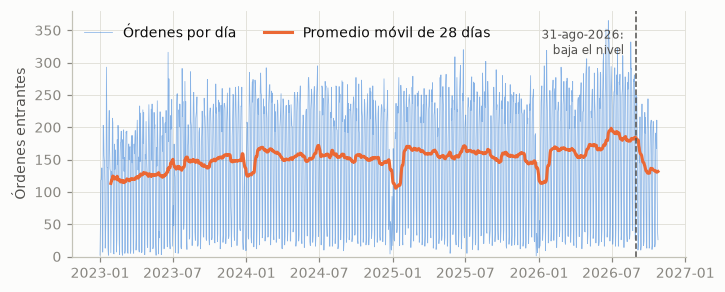

In [7]:
# Figura 1. Serie diaria y promedio móvil de 28 días
fig, ax = plt.subplots(figsize=(7.2, 2.9))
ax.plot(serie.index, serie.values, color=C["azul"], lw=0.5, alpha=0.55, label="Órdenes por día")
ax.plot(serie.index, serie.rolling(28).mean(), color=C["naranja"], lw=2, label="Promedio móvil de 28 días")
ax.axvline(pd.Timestamp("2026-08-31"), color=C["tinta2"], lw=1, ls="--")
ax.annotate("31-ago-2026:\nbaja el nivel", xy=(pd.Timestamp("2026-08-31"), 330), xytext=(-8, 0),
            textcoords="offset points", ha="right", va="center", fontsize=8, color=C["tinta2"])
ax.set(ylabel="Órdenes entrantes", ylim=(0, 380))
ax.legend(loc="upper left", ncol=2)
fig.savefig("figuras/fig1_serie_diaria.png"); plt.show()

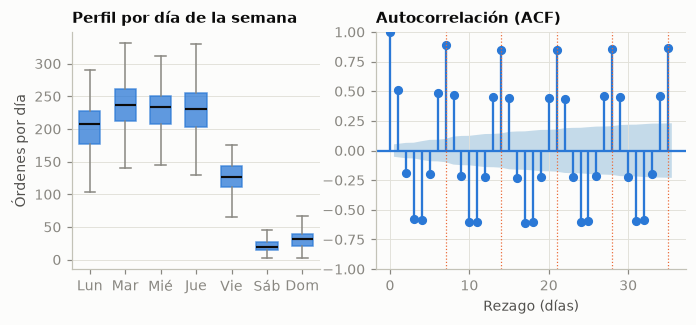

ACF rezago 1: 0.51 | 3: -0.58 | 4: -0.58 | 7: 0.89 | 14: 0.85 | 21: 0.85


In [8]:
# Figura 2. Perfil semanal (caja por día) y autocorrelación de la serie
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.8), gridspec_kw={"width_ratios": [1, 1.25]})
cajas = [serie[serie.index.dayofweek == k].values for k in range(7)]
bp = a1.boxplot(cajas, tick_labels=nombres_dia, patch_artist=True, widths=0.6, showfliers=False,
                medianprops=dict(color=C["tinta"], lw=1.4), whiskerprops=dict(color=C["tenue"]), capprops=dict(color=C["tenue"]))
for b in bp["boxes"]:
    b.set(facecolor=C["azul"], alpha=0.75, edgecolor=C["azul"])
a1.set(ylabel="Órdenes por día", title="Perfil por día de la semana")
a1.grid(axis="x", visible=False)
plot_acf(serie, lags=35, ax=a2, color=C["azul"], vlines_kwargs=dict(colors=C["azul"]), alpha=0.05, title="Autocorrelación (ACF)")
a2.set(xlabel="Rezago (días)")
for r in (7, 14, 21, 28, 35):
    a2.axvline(r, color=C["naranja"], lw=0.8, ls=":")
fig.savefig("figuras/fig2_perfil_semanal_acf.png"); plt.show()
a = acf(serie, nlags=35)
print("ACF rezago 1: %.2f | 3: %.2f | 4: %.2f | 7: %.2f | 14: %.2f | 21: %.2f" % (a[1], a[3], a[4], a[7], a[14], a[21]))

Fuerza de la tendencia: 0.29 | Fuerza de la estacionalidad semanal: 0.89


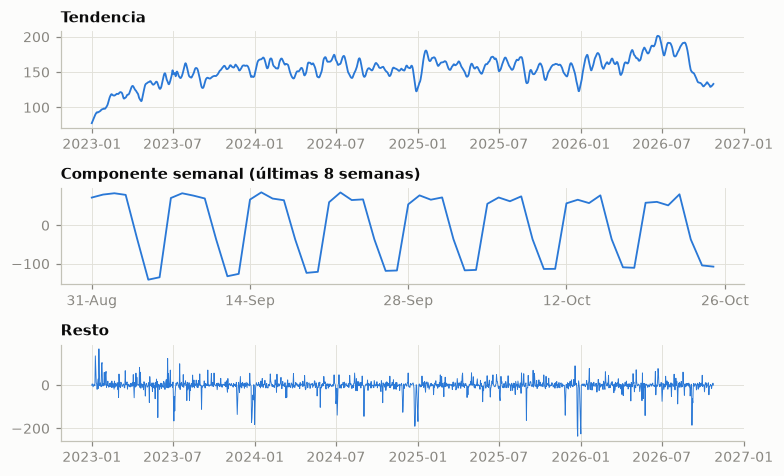

In [9]:
# Figura 3. Descomposición STL robusta con período 7
stl = STL(serie, period=7, robust=True).fit()
Ft = max(0, 1 - np.var(stl.resid) / np.var(stl.trend + stl.resid))
Fs = max(0, 1 - np.var(stl.resid) / np.var(stl.seasonal + stl.resid))
print("Fuerza de la tendencia: %.2f | Fuerza de la estacionalidad semanal: %.2f" % (Ft, Fs))

fig, ax = plt.subplots(3, 1, figsize=(7.2, 4.4))
ax[0].plot(stl.trend, color=C["azul"], lw=1.2); ax[0].set_title("Tendencia")
ax[1].plot(stl.seasonal["2026-08-31":], color=C["azul"], lw=1.2); ax[1].set_title("Componente semanal (últimas 8 semanas)")
ax[2].plot(stl.resid, color=C["azul"], lw=0.6); ax[2].set_title("Resto")
ax[1].xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2)); ax[1].xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
fig.tight_layout(); fig.savefig("figuras/fig3_stl.png"); plt.show()

                        mean  count
feriado                            
Navidad                 0.03      3
Año Nuevo               0.10      4
Labor Day               0.23      4
Thanksgiving            0.37      3
4 de julio              0.40      4
Memorial Day            0.42      4
Columbus Day            0.81      4
Día de los Presidentes  0.86      4
Día de M. L. King       0.96      4
Juneteenth              1.02      4
Veterans Day            1.03      3

Promedio de todos los feriados laborables: 0.57 del volumen normal (n=41)


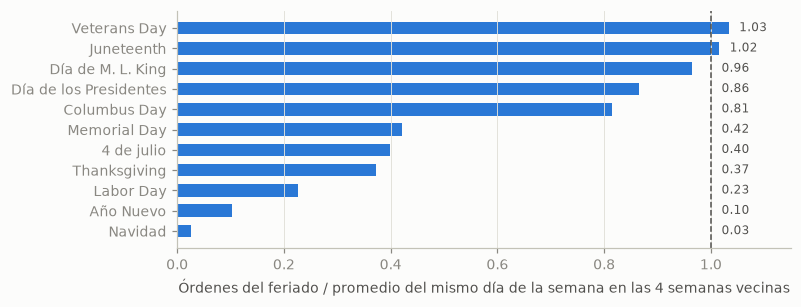

In [10]:
# Figura 4. Efecto de los feriados de EE. UU.: cuánto se aleja el feriado de un día laborable normal
es = {"New Year's Day": "Año Nuevo", "Martin Luther King Jr. Day": "Día de M. L. King", "Washington's Birthday": "Día de los Presidentes",
      "Memorial Day": "Memorial Day", "Juneteenth National Independence Day": "Juneteenth", "Independence Day": "4 de julio",
      "Labor Day": "Labor Day", "Columbus Day": "Columbus Day", "Veterans Day": "Veterans Day",
      "Thanksgiving Day": "Thanksgiving", "Christmas Day": "Navidad"}
filas = []
for f, nombre in sorted(US.items()):
    f = pd.Timestamp(f)
    if f < serie.index[0] or f > serie.index[-1] or f.dayofweek >= 5:
        continue
    vec = [f + pd.Timedelta(days=k) for k in (-14, -7, 7, 14)]
    vec = [v for v in vec if v in serie.index and v not in fer]       # mismo día de semana, sin feriados
    filas.append(dict(fecha=f, feriado=es.get(nombre.replace(" (observed)", ""), nombre), obs=serie[f], ref=serie[vec].mean()))
fer_df = pd.DataFrame(filas)
fer_df["razon"] = fer_df.obs / fer_df.ref
res_fer = fer_df.groupby("feriado").razon.agg(["mean", "count"]).sort_values("mean")
print(res_fer.round(2).to_string())
print("\nPromedio de todos los feriados laborables: %.2f del volumen normal (n=%d)" % (fer_df.razon.mean(), len(fer_df)))

fig, ax = plt.subplots(figsize=(7.2, 2.8))
ax.barh(res_fer.index, res_fer["mean"], color=C["azul"], height=0.62)
ax.axvline(1, color=C["tinta2"], lw=1, ls="--")
for i, v in enumerate(res_fer["mean"]):
    ax.text(max(v, 1.0) + 0.02, i, f"{v:.2f}", va="center", fontsize=8, color=C["tinta2"])
ax.set(xlabel="Órdenes del feriado / promedio del mismo día de la semana en las 4 semanas vecinas", xlim=(0, 1.15))
ax.grid(axis="y", visible=False)
fig.savefig("figuras/fig4_feriados.png"); plt.show()

## 4. Primer modelo: identificación del SARIMA

In [11]:
# Estacionariedad: ADF (H0: raíz unitaria; p bajo = estacionaria) y KPSS (H0: estacionaria; p bajo = no estacionaria)
# Nota: statsmodels acota el p-valor de KPSS al rango [0.01, 0.10].
for etiqueta, x in [("serie original", serie), ("tras diferencia estacional (1 - B^7)", serie.diff(7).dropna())]:
    print("%-38s ADF p = %.4f | KPSS p = %.2f" % (etiqueta, adfuller(x)[1], kpss(x, nlags="auto")[1]))

serie original                         ADF p = 0.0000 | KPSS p = 0.01
tras diferencia estacional (1 - B^7)   ADF p = 0.0000 | KPSS p = 0.10


In [12]:
# Ventana expansiva: origenes cada 14 días, horizonte de 14 días. El primer entrenamiento termina en corte_inicial.
H, PASO, M, N_VENT = 14, 14, 7, 46
datos = serie.reset_index()
datos.columns = ["ds", "y"]
datos.insert(0, "unique_id", "ordenes")
corte_inicial = datos.ds.max() - pd.Timedelta(days=H) - pd.Timedelta(days=PASO * (N_VENT - 1))
print("Primer corte:", corte_inicial.date(), "| último corte:", (datos.ds.max() - pd.Timedelta(days=H)).date(),
      "| días de entrenamiento en el primer corte:", int((datos.ds <= corte_inicial).sum()))

# Identificación del orden SOLO con datos anteriores al primer corte (sin mirar la prueba)
sf_id = StatsForecast(models=[AutoARIMA(season_length=M)], freq="D")
sf_id.fit(datos[datos.ds <= corte_inicial])
p, q, P, Q, m_, d, D = sf_id.fitted_[0, 0].model_["arma"]          # convención de statsforecast: (p, q, P, Q, m, d, D)
print("AutoARIMA eligió SARIMA(%d,%d,%d)(%d,%d,%d)[%d]" % (p, d, q, P, D, Q, m_))

Primer corte: 2025-01-19 | último corte: 2026-10-11 | días de entrenamiento en el primer corte: 750


AutoARIMA eligió SARIMA(2,0,1)(0,1,2)[7]


## 5. Validación de ventana expansiva contra los modelos de referencia

In [13]:
nombres = ["SNAIVE", "SNAIVE_prom4", "AutoETS", "SARIMA"]
modelos = [SeasonalNaive(season_length=M, alias="SNAIVE"),                           # repite el mismo día de la semana anterior
           SeasonalWindowAverage(season_length=M, window_size=4, alias="SNAIVE_prom4"),  # promedio del mismo día en las 4 semanas previas
           AutoETS(season_length=M, alias="AutoETS"),
           ARIMA(order=(p, d, q), season_length=M, seasonal_order=(P, D, Q), alias="SARIMA")]   # orden fijo, coeficientes reestimados en cada ventana
sf = StatsForecast(models=modelos, freq="D", n_jobs=1)
cv = sf.cross_validation(df=datos, h=H, step_size=PASO, n_windows=N_VENT, refit=True)
assert cv.cutoff.min() == corte_inicial and cv.cutoff.nunique() == N_VENT
for nom in nombres:
    cv[nom] = cv[nom].clip(lower=0)                                                   # restricción: los conteos no son negativos
print("Pronósticos evaluados:", len(cv), "(", cv.cutoff.nunique(), "ventanas x", H, "días )")

Pronósticos evaluados: 644 ( 46 ventanas x 14 días )


In [14]:
def escala_mase(corte):
    """Error absoluto medio del ingenuo estacional (m = 7) dentro del entrenamiento hasta `corte`."""
    ent = serie[:corte].values
    return np.mean(np.abs(ent[M:] - ent[:-M]))

filas = []
for corte, g in cv.groupby("cutoff"):
    esc = escala_mase(corte)
    for nom in nombres:
        e = g["y"] - g[nom]
        filas.append(dict(corte=corte, modelo=nom, mae=np.mean(np.abs(e)), mase=np.mean(np.abs(e)) / esc))
met = pd.DataFrame(filas)

def tabla(sub_cv, sub_met):
    out = pd.DataFrame({
        "MAE": {n: np.mean(np.abs(sub_cv["y"] - sub_cv[n])) for n in nombres},
        "RMSE": {n: np.sqrt(np.mean((sub_cv["y"] - sub_cv[n]) ** 2)) for n in nombres},
        "MASE (prom.)": sub_met.groupby("modelo").mase.mean(),
        "MASE (mediana)": sub_met.groupby("modelo").mase.median()}).loc[nombres]
    return out.round(3)

print("TODAS LAS VENTANAS (n = %d)" % met.corte.nunique())
print(tabla(cv, met).to_string())
pv = met.pivot(index="corte", columns="modelo", values="mase")
print("\nVentanas en que SARIMA tiene menor MASE que SNAIVE: %d de %d" % ((pv.SARIMA < pv.SNAIVE).sum(), len(pv)))
print("Prueba de Wilcoxon (SARIMA vs SNAIVE, MASE por ventana): p = %.4f" % wilcoxon(pv.SARIMA, pv.SNAIVE).pvalue)

TODAS LAS VENTANAS (n = 46)
                    MAE       RMSE  MASE (prom.)  MASE (mediana)
SNAIVE        29.929001  46.282001         1.022           0.886
SNAIVE_prom4  25.309000  39.238998         0.864           0.714
AutoETS       24.069000  37.772999         0.822           0.667
SARIMA        23.539000  36.020000         0.804           0.694

Ventanas en que SARIMA tiene menor MASE que SNAIVE: 38 de 46
Prueba de Wilcoxon (SARIMA vs SNAIVE, MASE por ventana): p = 0.0000


In [15]:
# Antes y después del cambio de nivel (ventanas cuyo pronóstico empieza el 31-ago-2026 o después)
quiebre = pd.Timestamp("2026-08-31")
post = cv.cutoff >= quiebre - pd.Timedelta(days=1)
print("ANTES DEL CAMBIO DE NIVEL (n = %d ventanas)" % cv[~post].cutoff.nunique())
print(tabla(cv[~post], met[met.corte < quiebre - pd.Timedelta(days=1)]).to_string())
print("\nDESDE EL CAMBIO DE NIVEL (n = %d ventanas)" % cv[post].cutoff.nunique())
print(tabla(cv[post], met[met.corte >= quiebre - pd.Timedelta(days=1)]).to_string())

# Sesgo del SARIMA por periodo (pronóstico medio contra real medio)
for etiqueta, g in [("antes del cambio", cv[~post]), ("desde el cambio", cv[post])]:
    print("Sesgo %-17s pronóstico medio %.1f vs real medio %.1f (%+.0f %%)" % (etiqueta + ":", g.SARIMA.mean(), g.y.mean(), 100 * (g.SARIMA.sum() / g.y.sum() - 1)))

# Cercanía a feriados: día feriado, el anterior o el siguiente
cerca = set()
for f in fer:
    for k in (-1, 0, 1):
        cerca.add(f + pd.Timedelta(days=k))
cv["cerca_feriado"] = cv.ds.isin(cerca)
ae = pd.DataFrame({n: (cv["y"] - cv[n]).abs() for n in nombres}).assign(cerca_feriado=cv.cerca_feriado.values)
print("\nMAE por cercanía a feriados (n días: normales = %d, cercanos = %d)" % ((~ae.cerca_feriado).sum(), ae.cerca_feriado.sum()))
print(ae.groupby("cerca_feriado")[nombres].mean().rename(index={False: "día normal", True: "feriado ±1 día"}).round(1).to_string())

ANTES DEL CAMBIO DE NIVEL (n = 42 ventanas)
                    MAE       RMSE  MASE (prom.)  MASE (mediana)
SNAIVE        29.448999  45.222000         1.006           0.886
SNAIVE_prom4  25.215000  38.641998         0.860           0.714
AutoETS       23.870001  37.310001         0.815           0.672
SARIMA        22.493000  34.623001         0.768           0.678

DESDE EL CAMBIO DE NIVEL (n = 4 ventanas)
                    MAE       RMSE  MASE (prom.)  MASE (mediana)
SNAIVE        34.964001  56.220001         1.196           1.123
SNAIVE_prom4  26.295000  45.030998         0.900           0.627
AutoETS       26.152000  42.325001         0.895           0.556
SARIMA        34.519001  48.305000         1.181           1.010
Sesgo antes del cambio: pronóstico medio 156.9 vs real medio 162.1 (-3 %)
Sesgo desde el cambio:  pronóstico medio 163.9 vs real medio 131.8 (+24 %)

MAE por cercanía a feriados (n días: normales = 590, cercanos = 54)
                   SNAIVE  SNAIVE_prom4    Au

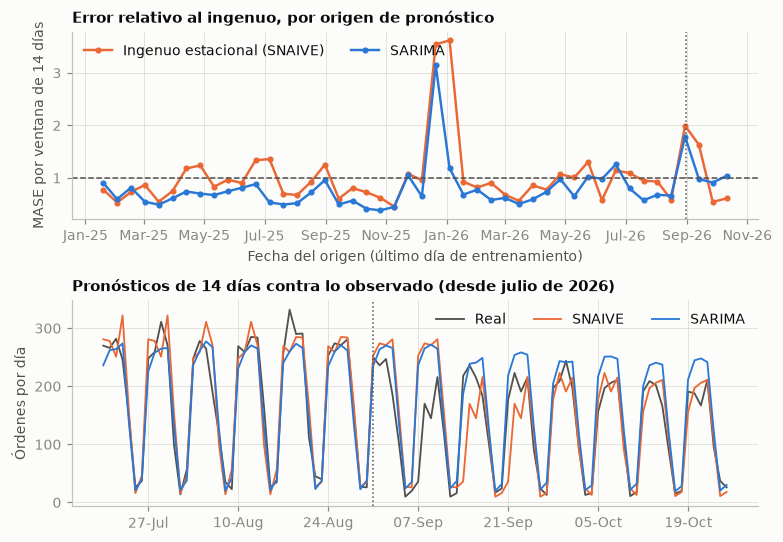

In [16]:
# Figura 5. MASE por ventana y comparación visual en el tramo más reciente
fig, (a1, a2) = plt.subplots(2, 1, figsize=(7.2, 5.0), gridspec_kw={"height_ratios": [1, 1.1]})
a1.plot(pv.index, pv.SNAIVE, color=C["naranja"], lw=1.6, marker="o", ms=3, label="Ingenuo estacional (SNAIVE)")
a1.plot(pv.index, pv.SARIMA, color=C["azul"], lw=1.6, marker="o", ms=3, label="SARIMA")
a1.axhline(1, color=C["tinta2"], lw=1, ls="--")
a1.axvline(quiebre, color=C["tinta2"], lw=1, ls=":")
a1.set(ylabel="MASE por ventana de 14 días", title="Error relativo al ingenuo, por origen de pronóstico", xlabel="Fecha del origen (último día de entrenamiento)")
a1.legend(loc="upper left", ncol=2)
a1.xaxis.set_major_locator(mdates.MonthLocator(interval=2)); a1.xaxis.set_major_formatter(mdates.DateFormatter("%b-%y"))

reciente = cv[cv.cutoff >= pd.Timestamp("2026-07-19")].sort_values("ds")
a2.plot(serie["2026-07-20":].index, serie["2026-07-20":].values, color=C["tinta2"], lw=1.2, label="Real")
a2.plot(reciente.ds, reciente.SNAIVE, color=C["naranja"], lw=1.2, label="SNAIVE")
a2.plot(reciente.ds, reciente.SARIMA, color=C["azul"], lw=1.2, label="SARIMA")
a2.axvline(quiebre, color=C["tinta2"], lw=1, ls=":")
a2.set(ylabel="Órdenes por día", title="Pronósticos de 14 días contra lo observado (desde julio de 2026)")
a2.legend(loc="upper right", ncol=3)
a2.xaxis.set_major_locator(mdates.WeekdayLocator(byweekday=0, interval=2)); a2.xaxis.set_major_formatter(mdates.DateFormatter("%d-%b"))
fig.tight_layout(); fig.savefig("figuras/fig5_validacion.png"); plt.show()

## 6. Diagnóstico de residuos y pronóstico a 14 días

Ljung-Box sobre los residuos (gl ajustados por 5 parámetros ARMA):
    lb_stat  lb_pvalue
14  39.5056     0.0000
28  57.9349     0.0001

Ljung-Box con residuos de feriados anulados: {14: 0.0, 28: 0.0}
Autocorrelación de los residuos: rezago 6 = 0.13 | rezago 8 = 0.09


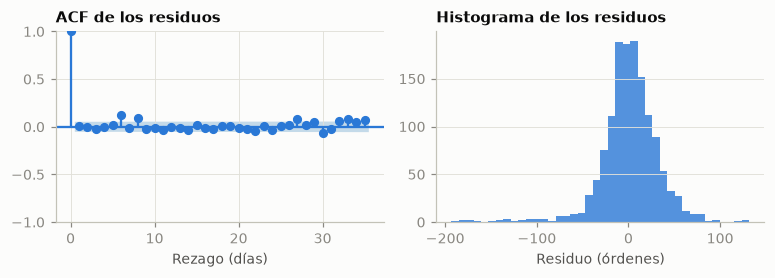

Residuos: media 1.42 | desviación 31.8 | asimetría -1.13


In [17]:
sf_final = StatsForecast(models=[ARIMA(order=(p, d, q), season_length=M, seasonal_order=(P, D, Q), alias="SARIMA")], freq="D")
pron = sf_final.forecast(df=datos, h=H, level=[80, 95], fitted=True)
ajuste = sf_final.forecast_fitted_values()
res = (ajuste["y"] - ajuste["SARIMA"]).iloc[2 * M:]                                   # se descartan los primeros 14 días (arranque de la diferenciación)
lb = acorr_ljungbox(res, lags=[14, 28], model_df=p + q + P + Q)
print("Ljung-Box sobre los residuos (gl ajustados por %d parámetros ARMA):" % (p + q + P + Q))
print(lb.round(4).to_string())

# Sensibilidad: se anulan los residuos de los feriados (±1 día) y se repite la prueba
res.index = ajuste["ds"].iloc[2 * M:].values
res_sin_fer = res.where(~res.index.isin(cerca), 0)
lb2 = acorr_ljungbox(res_sin_fer, lags=[14, 28], model_df=p + q + P + Q)
print("\nLjung-Box con residuos de feriados anulados:", lb2.lb_pvalue.round(4).to_dict())
a_res = acf(res, nlags=10)
print("Autocorrelación de los residuos: rezago 6 = %.2f | rezago 8 = %.2f" % (a_res[6], a_res[8]))

fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.2, 2.6))
plot_acf(res, lags=35, ax=a1, color=C["azul"], vlines_kwargs=dict(colors=C["azul"]), alpha=0.05, title="ACF de los residuos")
a1.set(xlabel="Rezago (días)")
a2.hist(res, bins=40, color=C["azul"], alpha=0.8); a2.set(title="Histograma de los residuos", xlabel="Residuo (órdenes)")
a2.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig("figuras/fig6_residuos.png"); plt.show()
print("Residuos: media %.2f | desviación %.1f | asimetría %.2f" % (res.mean(), res.std(), res.skew()))

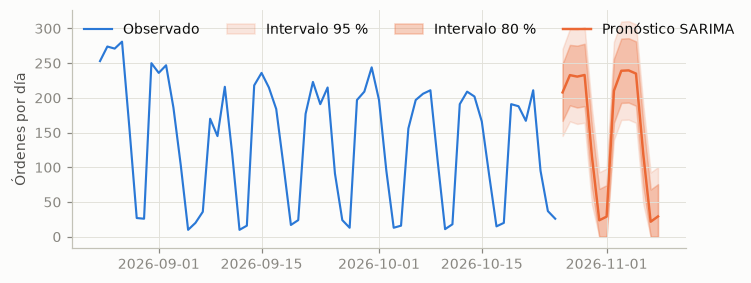

        ds  SARIMA  SARIMA-lo-80  SARIMA-hi-80
Mon 26-Oct   208.0         167.0         249.0
Tue 27-Oct   233.0         189.0         276.0
Wed 28-Oct   231.0         186.0         275.0
Thu 29-Oct   233.0         188.0         278.0
Fri 30-Oct   116.0          71.0         161.0
Sat 31-Oct    24.0         -21.0          69.0
Sun 01-Nov    29.0         -16.0          74.0
Mon 02-Nov   210.0         164.0         256.0
Tue 03-Nov   239.0         193.0         285.0
Wed 04-Nov   240.0         193.0         286.0
Thu 05-Nov   235.0         189.0         281.0
Fri 06-Nov   118.0          72.0         165.0
Sat 07-Nov    22.0         -25.0          68.0
Sun 08-Nov    29.0         -17.0          76.0

Total pronosticado, próximas 2 semanas: 2166 órdenes (las 2 semanas anteriores: 1807)


In [18]:
# Pronóstico a 14 días (26-oct a 8-nov-2026), con intervalos del 80 % y 95 %
pron["fecha"] = pron.ds
fig, ax = plt.subplots(figsize=(7.2, 2.8))
hist = serie["2026-08-24":]
ax.plot(hist.index, hist.values, color=C["azul"], lw=1.4, label="Observado")
ax.fill_between(pron.ds, pron["SARIMA-lo-95"].clip(lower=0), pron["SARIMA-hi-95"], color=C["naranja"], alpha=0.15, label="Intervalo 95 %")
ax.fill_between(pron.ds, pron["SARIMA-lo-80"].clip(lower=0), pron["SARIMA-hi-80"], color=C["naranja"], alpha=0.30, label="Intervalo 80 %")
ax.plot(pron.ds, pron.SARIMA.clip(lower=0), color=C["naranja"], lw=1.6, label="Pronóstico SARIMA")
ax.set(ylabel="Órdenes por día"); ax.legend(loc="upper left", ncol=4)
fig.savefig("figuras/fig7_pronostico.png"); plt.show()
print(pron[["ds", "SARIMA", "SARIMA-lo-80", "SARIMA-hi-80"]].round(0).assign(ds=lambda x: x.ds.dt.strftime("%a %d-%b")).to_string(index=False))
print("\nTotal pronosticado, próximas 2 semanas: %.0f órdenes (las 2 semanas anteriores: %d)" % (pron.SARIMA.clip(lower=0).sum(), serie[-14:].sum()))

## 7. Conclusiones del primer modelo

- **Frente a las referencias.** El SARIMA(2,0,1)(0,1,2)[7] reduce el error del ingenuo estacional: MASE promedio de 0.80 contra 1.02 y MAE de 23.5 contra 29.9 órdenes por día (21 % menos). Gana en 38 de las 46 ventanas (Wilcoxon, p < 0.001). Frente a las referencias más fuertes la ventaja es pequeña: AutoETS (MASE 0.82) y el promedio de 4 semanas (0.86).
- **Dónde falla.** (1) Alrededor de feriados de EE. UU. el MAE sube a unas 54 órdenes, contra 21 en días normales, y ningún modelo lo corrige. (2) Desde el 31 de agosto de 2026 el nivel bajó cerca de 28 % y el SARIMA sobrestima 24 % (MASE 1.18, peor que AutoETS con 0.90). (3) La prueba de Ljung-Box rechaza ruido blanco en los residuos, aunque la autocorrelación restante es pequeña (cerca de 0.1 en los rezagos 6 y 8) y persiste al anular los residuos de los días de feriado.
- **Lectura del pronóstico a 14 días.** Suma 2,166 órdenes contra 1,807 de las dos semanas previas. Por el sesgo descrito en (2), conviene leerlo como un techo probable, no como un valor central confiable.
- **Siguiente paso.** Un segundo método que incorpore variables externas conocidas de antemano (día de la semana, feriados de EE. UU. y sus vecinos) y que se adapte a cambios de nivel (regresión regularizada con variables de calendario, y Prophet o Chronos-2 como contraste).